# PathSnap — Bayesian Hyperparameter Optimisation (executed)
**Owner:** Pandu

**What we say:** After comparing five models we selected **LightGBM**: best student-test Top-1 accuracy (86.04%), fast training, sub-second inference for the API, and good probabilities for the HMM. We then tuned it with **Bayesian optimisation** (Optuna, TPE sampler).

*Executed notebook: every output below is real. The 30-trial search itself takes about 40 minutes, so this notebook loads its saved record (`results/bayes_opt/`); set `RUN_SEARCH = True` to rerun it.*

## Step 1 — Setup

In [1]:
# Works on Google Colab (clones repo, data from Drive) or locally inside the repo
import os, sys
try:
    import google.colab  # noqa
    from google.colab import drive; drive.mount('/content/drive')
    !git clone -q https://github.com/GTX-Pradeep/Path_Snap_PT_096.git /content/pathsnap
    !pip install -q lightgbm optuna pyarrow folium
    os.environ['PATHSNAP_DATA'] = '/content/drive/MyDrive/Student folder'   # <- dataset location
    os.chdir('/content/pathsnap/src')
except ImportError:
    os.chdir(os.path.join(os.path.dirname(os.path.abspath('.')), 'src') if os.path.basename(os.path.abspath('.')) == 'notebooks' else 'src')
sys.path.insert(0, '.')
import pandas as pd, json
from IPython.display import Image, display
pd.set_option('display.width', 200)
print('working dir:', os.getcwd())

working dir: /home/user/pathsnap/src


## Step 2 — Search space, objective and settings
**What we say:**
* **Hyperparameters and ranges:** number of trees, learning rate (log scale), leaves per tree, minimum samples per leaf, row/column subsampling, L1/L2 regularisation and class-imbalance handling.
* **Objective:** mean candidate-level **macro F1 over 3-fold GroupKFold by trip**, using only the 80 training trips. Student-test and evaluator data are never used in the search.
* **Why Bayesian:** TPE builds a probability model of which settings score well and samples the next trial where improvement is likely. It needs far fewer trials than grid search.
* **Median pruner:** stops a trial after its first fold if it is already worse than the median. **Trial 0 = the untuned defaults**, so the search starts from the baseline.

In [2]:
RUN_SEARCH = False
if RUN_SEARCH:
    !python bayes_opt.py 30
bo = json.load(open('../results/bayes_opt/best_params.json'))
print('objective :', bo['objective']); print('sampler   :', bo['sampler'], '|', bo['pruner'])
print('trials    :', bo['n_trials'], '(complete', bo['n_complete'], ', pruned', bo['n_pruned'], ')')
print('search time: %.1f min' % (bo['search_time_s'] / 60))
pd.DataFrame(bo['search_space'].items(), columns=['hyperparameter', 'range / distribution'])

objective : mean macro F1, 3-fold GroupKFold by trip
sampler   : TPE (seed 42) | MedianPruner
trials    : 30 (complete 23 , pruned 7 )
search time: 15.4 min


,hyperparameter,range / distribution
0,n_estimators,int 100..600
1,learning_rate,log-uniform 0.01..0.2
2,num_leaves,int log 15..255
3,min_child_samples,int log 10..300
4,subsample,uniform 0.5..1.0
5,colsample_bytree,uniform 0.5..1.0
6,reg_lambda,log-uniform 1e-3..10
7,reg_alpha,log-uniform 1e-3..10
8,is_unbalance,"categorical {True, False}"


## Step 3 — Every trial (the optimisation record)
**What we say:** Each row is one trial: the hyperparameters tried and the CV macro F1 obtained. Pruned trials were stopped early.

In [3]:
trials = pd.read_csv('../results/bayes_opt/trials.csv')
cols = ['number', 'value', 'state'] + [c for c in trials.columns if c.startswith('params_')]
trials[cols].sort_values('value', ascending=False).round(4)

,number,value,state,params_colsample_bytree,params_is_unbalance,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_alpha,params_reg_lambda,params_subsample
27,27,0.9141,PRUNED,0.7445,False,0.0232,36,550,126,0.2633,0.0123,0.5273
25,25,0.9140,PRUNED,0.6766,False,0.0204,46,450,215,2.7681,0.0015,0.6186
21,21,0.9134,PRUNED,0.7274,False,0.0464,86,400,133,0.8313,0.0179,0.5763
19,19,0.9132,PRUNED,0.8449,False,0.0575,47,300,194,1.6169,0.0195,0.7027
20,20,0.9130,COMPLETE,0.7388,False,0.0141,32,450,237,1.7050,0.0039,0.7158
24,24,0.9129,COMPLETE,0.8514,False,0.0179,33,300,209,0.3802,0.0485,0.5582
29,29,0.9129,COMPLETE,0.7359,False,0.0145,34,500,221,2.7461,0.0011,0.5493
26,26,0.9129,COMPLETE,0.7998,False,0.0143,30,450,121,0.1844,0.0774,0.5529
7,7,0.9129,COMPLETE,0.7713,False,0.0225,33,300,156,1.6173,0.0037,0.6405
23,23,0.9128,COMPLETE,0.8176,False,0.0139,21,300,187,0.8920,0.0074,0.5482


## Step 4 — Optimisation history and hyperparameter importance
**What we say:** The red line is the best score found so far. It rises above trial 0 (the untuned defaults) early in the search, then levels off. The importance plot (fANOVA) shows which hyperparameters mattered most.

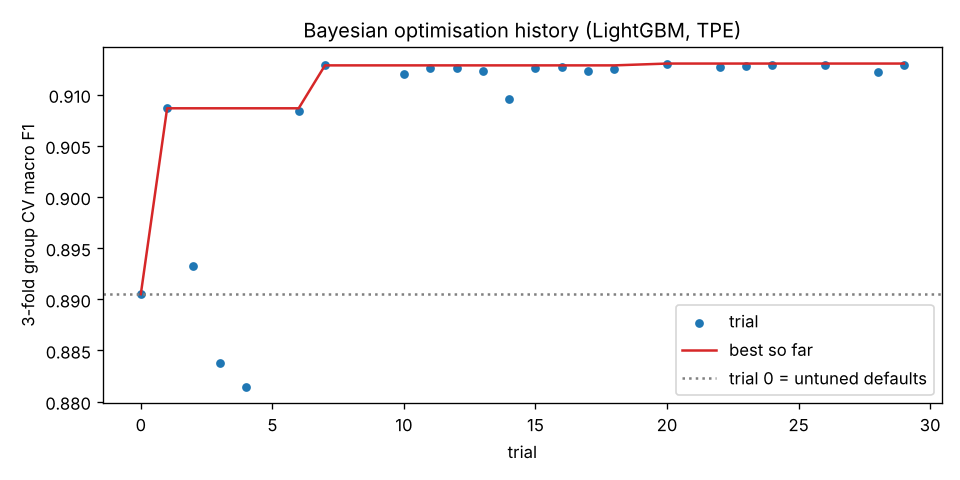

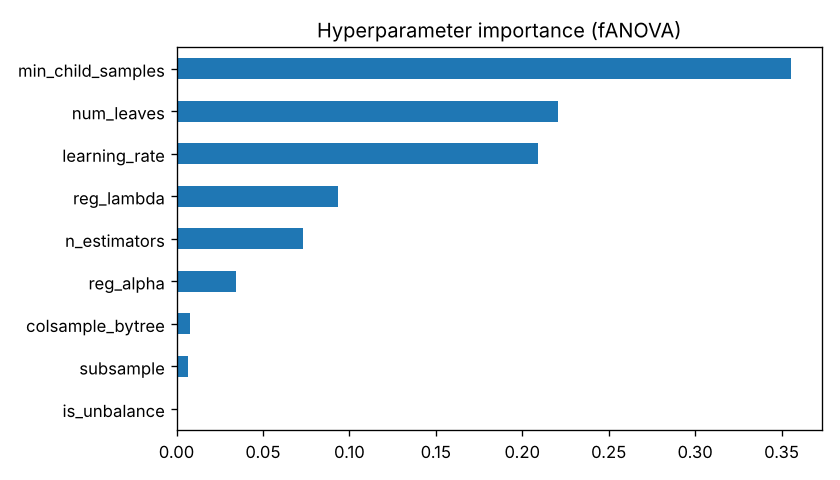

best params: {'n_estimators': 450, 'learning_rate': 0.014141481809095736, 'num_leaves': 237, 'min_child_samples': 32, 'subsample': 0.7157500888266711, 'colsample_bytree': 0.7387738637541865, 'reg_lambda': 0.003946992942746613, 'reg_alpha': 1.7050396561701195, 'is_unbalance': False}
best 3-fold CV macro F1: 0.9130


In [4]:
display(Image('../results/bayes_opt/optimisation_history.png'))
display(Image('../results/bayes_opt/param_importance.png'))
print('best params:', bo['best_params'])
print('best 3-fold CV macro F1: %.4f' % bo['best_cv3_macro_f1'])

## Step 5 — Tuned vs untuned (same protocol: 5-fold group CV + 10 student-test trips)
**What we say:** The best parameters were refitted on all training data and evaluated exactly like the five original models. Positive change = better, except log loss and times, where lower is better.

In [5]:
tvu = pd.read_csv('../results/bayes_opt/tuned_vs_untuned.csv', index_col=0)
tvu.round(4)

,untuned,tuned,change
cv_macro_f1_mean,0.8887,0.9132,0.0245
test_top1_accuracy,0.8604,0.8637,0.0033
test_macro_f1,0.8897,0.9185,0.0287
test_log_loss,0.1419,0.0918,-0.0501
train_time_s,10.8399,18.3405,7.5006
inference_time_s,0.6107,1.6282,1.0175


## Step 6 — Diagnostics of the tuned model, and the comparison with all models

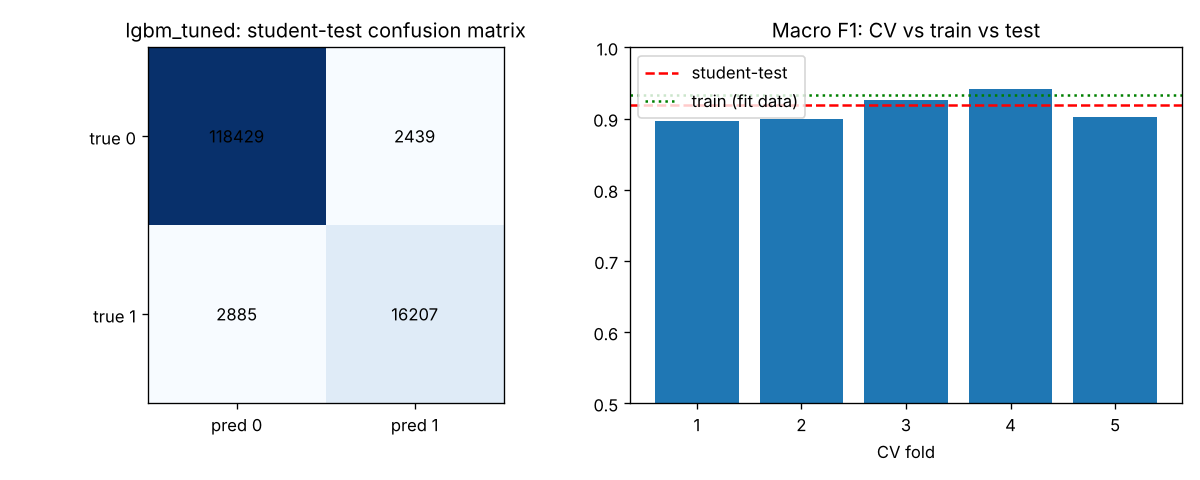

,model,family,cv_macro_f1_mean,cv_macro_f1_std,train_macro_f1,test_macro_f1,test_precision,test_recall,test_log_loss,test_top1_accuracy,train_time_s,inference_time_s
2,lgbm_tuned,Boosting (Bayesian-tuned),0.9132,0.0175,0.9333,0.9185,0.8692,0.8489,0.0918,0.8637,18.3405,1.6282
1,lgbm,Boosting,0.8887,0.0179,0.9000,0.8897,0.7104,0.9550,0.1419,0.8604,10.3241,0.5417
4,mlp,Neural network,0.9073,0.0172,0.9142,0.9157,0.8675,0.8409,0.0992,0.8565,21.2199,0.0510
5,rf,Ensemble (bagging),0.8943,0.0199,0.8970,0.8974,0.7364,0.9424,0.1395,0.8549,24.4390,0.2153
0,knn,Instance-based,0.9008,0.0139,1.0000,0.9069,0.8523,0.8257,0.1470,0.8485,0.8731,49.7044
3,logreg,Linear / probabilistic,0.8261,0.0130,0.8257,0.8287,0.5827,0.9363,0.2277,0.8479,7.2863,0.0254


In [6]:
display(Image('../results/plots/lgbm_tuned_diagnostics.png'))
from train_models import comparison_table
comparison_table().round(4)